Iteration: 1 Best Fitness: 2.631266919641698
Iteration: 2 Best Fitness: 1.1355397738023634
Iteration: 3 Best Fitness: 0.23964888088854813
Iteration: 4 Best Fitness: 0.12706472260635956
Iteration: 5 Best Fitness: 0.03174670171773935
Iteration: 6 Best Fitness: 0.005274214452961283
Iteration: 7 Best Fitness: 0.0004095671194877541
Iteration: 8 Best Fitness: 0.0004095671194877541
Iteration: 9 Best Fitness: 5.0191471475452315e-05
Iteration: 10 Best Fitness: 5.0191471475452315e-05
Iteration: 11 Best Fitness: 7.94040452375837e-06
Iteration: 12 Best Fitness: 4.195359092197328e-06
Iteration: 13 Best Fitness: 1.596091875898281e-08
Iteration: 14 Best Fitness: 1.596091875898281e-08
Iteration: 15 Best Fitness: 1.596091875898281e-08
Iteration: 16 Best Fitness: 5.058276168225237e-09
Iteration: 17 Best Fitness: 2.6493845091052137e-09
Iteration: 18 Best Fitness: 8.289488598445087e-11
Iteration: 19 Best Fitness: 8.289488598445087e-11
Iteration: 20 Best Fitness: 4.713427401707209e-12
Iteration: 21 Best Fi

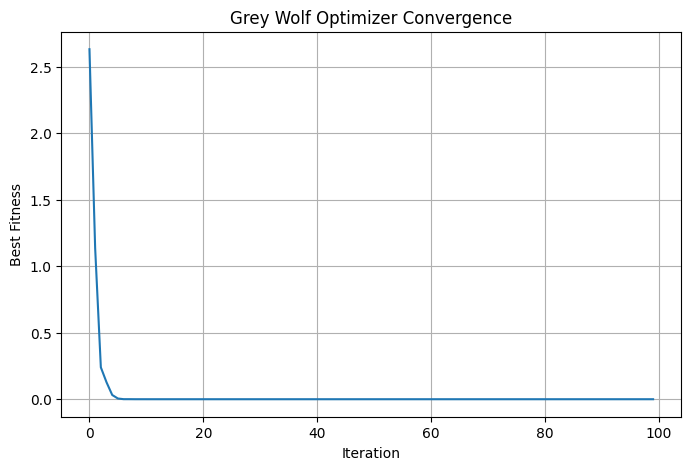

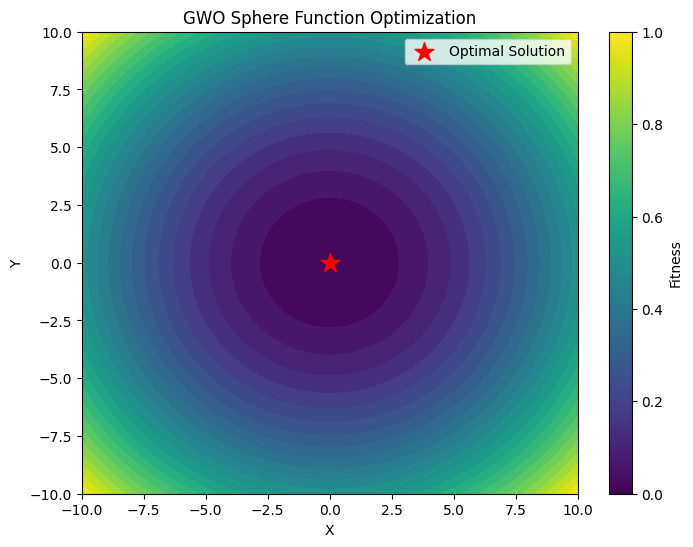

In [1]:

import numpy as np
import matplotlib.pyplot as plt

n_wolves = 30
dimensions = 2
iterations = 100

lower_bound = -10
upper_bound = 10

wolves = np.random.uniform(
    lower_bound, upper_bound,
    (n_wolves, dimensions)
)

def fitness(position):
    return np.sum(position ** 2)

alpha_position = np.zeros(dimensions)
beta_position = np.zeros(dimensions)
delta_position = np.zeros(dimensions)

alpha_score = float('inf')
beta_score = float('inf')
delta_score = float('inf')

convergence = []

for iteration in range(iterations):

    for i in range(n_wolves):

        wolves[i] = np.clip(
            wolves[i], lower_bound, upper_bound
        )

        score = fitness(wolves[i])

        if score < alpha_score:
            delta_score = beta_score
            delta_position = beta_position.copy()

            beta_score = alpha_score
            beta_position = alpha_position.copy()

            alpha_score = score
            alpha_position = wolves[i].copy()

        elif score < beta_score:
            delta_score = beta_score
            delta_position = beta_position.copy()

            beta_score = score
            beta_position = wolves[i].copy()

        elif score < delta_score:
            delta_score = score
            delta_position = wolves[i].copy()

    a = 2 - 2 * iteration / iterations

    for i in range(n_wolves):

        r1 = np.random.random(dimensions)
        r2 = np.random.random(dimensions)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = np.abs(
            C1 * alpha_position - wolves[i]
        )

        X1 = alpha_position - A1 * D_alpha

        r1 = np.random.random(dimensions)
        r2 = np.random.random(dimensions)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = np.abs(
            C2 * beta_position - wolves[i]
        )

        X2 = beta_position - A2 * D_beta

        r1 = np.random.random(dimensions)
        r2 = np.random.random(dimensions)

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = np.abs(
            C3 * delta_position - wolves[i]
        )

        X3 = delta_position - A3 * D_delta

        wolves[i] = (X1 + X2 + X3) / 3

    convergence.append(alpha_score)

    print(
        "Iteration:", iteration + 1,
        "Best Fitness:", alpha_score
    )

print("Alpha Wolf Position:", alpha_position)
print("Minimum Function Value:", alpha_score)

plt.figure(figsize=(8, 5))
plt.plot(convergence)
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("Grey Wolf Optimizer Convergence")
plt.grid()
plt.show()

x = np.linspace(lower_bound, upper_bound, 100)
y = np.linspace(lower_bound, upper_bound, 100)

X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=30, cmap='viridis')
plt.scatter(
    alpha_position[0],
    alpha_position[1],
    color='red',
    marker='*',
    s=200,
    label='Optimal Solution'
)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("GWO Sphere Function Optimization")
plt.legend()
plt.colorbar(label="Fitness")
plt.show()
